Compose a graphic of a sliced [Pitaya](https://en.wikipedia.org/wiki/Pitaya), a fruit also known as "dragon fruit".  

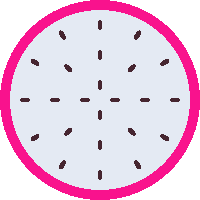

### Pitaya Seed

The small seeds of a pitaya are distributed all throughout the fruit.
They are dark (the color is already defined in `SEED_COLOR`)
and have an elliptical shape (about half as wide as long).

Implement the `pitaya_seed` function, using <API>ellipse</API>.

In [ ]:
from pytamaro import rgb_color, ellipse, show_graphic, Graphic

SEED_COLOR = rgb_color(70, 38, 48)

def pitaya_seed(diameter: float) -> Graphic:
    return #TODO

show_graphic(pitaya_seed(60))

In [2]:
#teacher-only
from pytamaro import rgb_color, ellipse, show_graphic, Graphic

SEED_COLOR = rgb_color(70, 38, 48)

def pitaya_seed(diameter: float) -> Graphic:
    return ellipse(diameter, diameter / 2, SEED_COLOR)

show_graphic(pitaya_seed(60))

### Sliced Pitaya without Seeds

Compose a sliced pitaya without any seeds.
Use the given colors for the skin (`SKIN_COLOR`) and the flesh (`FLESH_COLOR`).
The sliced pitaya should have the given overall `diameter`,
and the flesh should be 90% of that diameter.

In [ ]:
from pytamaro import overlay

SKIN_COLOR = rgb_color(249, 18, 141)
FLESH_COLOR = rgb_color(228, 234, 243)

def sliced_pitaya_without_seeds(diameter:float) -> Graphic:
    return #TODO

show_graphic(sliced_pitaya_without_seeds(200))

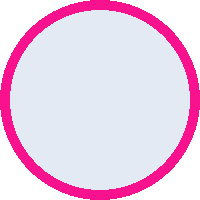

In [3]:
#teacher-only
from pytamaro import overlay

SKIN_COLOR = rgb_color(249, 18, 141)
FLESH_COLOR = rgb_color(228, 234, 243)

def sliced_pitaya_without_seeds(diameter:float) -> Graphic:
    return overlay(
        ellipse(diameter * 0.9, diameter * 0.9, FLESH_COLOR),
        ellipse(diameter, diameter, SKIN_COLOR)
    )

show_graphic(sliced_pitaya_without_seeds(200))

### Ring of Seeds

Create a function `ring` that produces a ring of `count` seeds, evenly spread across the 360 degrees of a circle.
The inside diameter of the ring should correspond to `diameter`
(the seeds should form a ring just outside the diameter).
Repetitively call `pitaya_seed` to produce the ring of seeds.

Here is an example of calling `ring(8, 100, pitaya_seed(20))`:

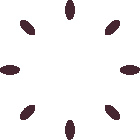


Hint: The seeds must be placed half the diameter away from the center of the ring.
To do that, create a <API>rectangle</API> that is as wide as the radius of the ring,
and that has a height of 0 (it will not be visible but acts as a gap).
Place that rectangle on the left of the seed.
Then pin that composition on its <API>center_left</API>,
and <API>rotate</API> by the necessary amount.

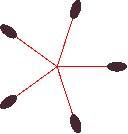

Above is an example of a ring with 5 seeds, showing this approach.
To make the rectangles visible, here they have a height of 1 instead of 0,
and they are colored in red.


In [ ]:
from pytamaro import empty_graphic, rotate, pin, beside, rectangle, red, center_left, compose

def ring(count: int, ringDiameter: float, seed: Graphic) -> Graphic:
    result = empty_graphic()
    #TODO
    return result

show_graphic(ring(8, 100, pitaya_seed(20)))

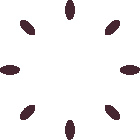

In [4]:
#teacher-only
from pytamaro import empty_graphic, rotate, pin, beside, rectangle, red, center_left, compose

def ring(count: int, ringDiameter: float, seed: Graphic) -> Graphic:
    result = empty_graphic()
    for i in range(count):
        angle = 360.0 / count * i
        s = rotate(
            angle,
            pin(
                center_left,
                beside(
                    rectangle(ringDiameter / 2, 0, red),
                    seed
                )
            )
        )
        result = compose(result, s)
    return result

show_graphic(ring(8, 100, pitaya_seed(20)))
#show_graphic(ring(5, 100, pitaya_seed(20)))

### Sliced Pitaya with Seeds
Create three rings of seeds:

* 10% of diameter - 4 seeds
* 40% of diameter - 8 seeds
* 70% of diameter - 12 seeds

Place them on top of a sliced pitaya without seeds.

In [ ]:
def sliced_pitaya(diameter: float) -> Graphic:
    return #TODO

show_graphic(sliced_pitaya(200))

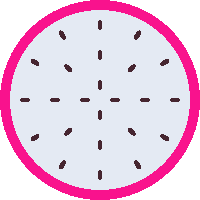

In [5]:
#teacher-only
from pytamaro import save_graphic

def sliced_pitaya(diameter: float) -> Graphic:
    return overlay(
        ring(12, diameter * 0.7, pitaya_seed(diameter * 0.05)),
        overlay(
            ring(8, diameter * 0.4, pitaya_seed(diameter * 0.05)),
            overlay(
                ring(4, diameter * 0.1, pitaya_seed(diameter * 0.05)),
                sliced_pitaya_without_seeds(diameter)
            )
        )
    )

show_graphic(sliced_pitaya(200))
save_graphic("sliced-pitaya.svg", sliced_pitaya(200))